# Algoritmo de Deutsch em Qiskit

Dada uma função booleana de 1 bit, $f$ de $\{0,1\}$ em $\{0,1\}$, queremos saber se ela é constante ou balanceada consultando o oráculo uma única vez.

Ao longo do notebook separamos duas coisas

- **$f$** é a função, descrita pela tabela verdade
- **$U_f$** é o oráculo, o circuito que implementa $f$ de forma reversível

In [ ]:
!pip install qiskit pylatexenc -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 45.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 28.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 1.9 MB/s eta 0:00:00


In [ ]:
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit.providers.basic_provider import BasicProvider

backend = BasicProvider().get_backend("basic_simulator")

## 1. As quatro funções de 1 bit

Cada coluna é uma função e cada linha é uma entrada $x$.

| $x$ | $f_0$ | $f_1$ | $f_2$ | $f_3$ |
|:---:|:---:|:---:|:---:|:---:|
| 0 | 0 | 0 | 1 | 1 |
| 1 | 0 | 1 | 0 | 1 |

A função é **constante** quando $f(0) = f(1)$ e **balanceada** quando $f(0) \neq f(1)$. Classicamente essa decisão exige duas consultas, uma para $f(0)$ e outra para $f(1)$.

In [ ]:
# Tabela verdade de cada função, f(x) para x = 0 e x = 1
tabela_verdade = {
    0: {0: 0, 1: 0},   # f0(x) = 0
    1: {0: 0, 1: 1},   # f1(x) = x
    2: {0: 1, 1: 0},   # f2(x) = NOT x
    3: {0: 1, 1: 1},   # f3(x) = 1
}

def tipo_classico(caso):
    # Decisão clássica, precisa conhecer f(0) e f(1)
    f = tabela_verdade[caso]
    return "constante" if f[0] == f[1] else "balanceada"

for caso, f in tabela_verdade.items():
    print(f"f{caso}   0 -> {f[0]}   1 -> {f[1]}   {tipo_classico(caso)}")

f0   0 -> 0   1 -> 0   constante
f1   0 -> 0   1 -> 1   balanceada
f2   0 -> 1   1 -> 0   balanceada
f3   0 -> 1   1 -> 1   constante


## 2. O oráculo $U_f$

Portas quânticas são reversíveis, mas $f_0$ e $f_3$ não são, porque levam as duas entradas na mesma saída. Por isso o oráculo usa dois qubits

$$U_f\,|x\rangle|j\rangle = |x\rangle|j \oplus f(x)\rangle$$

O qubit $q_0$ guarda $x$ e não muda. O qubit $q_1$ recebe $f(x)$ somado módulo 2.

O circuito sai direto da tabela verdade. Para cada $x$ com $f(x) = 1$, colocamos uma porta que inverte $q_1$ quando $q_0$ vale esse $x$.

| função | saídas 1 na tabela | portas |
|:---:|:---:|:---:|
| $f_0$ | nenhuma | $I \otimes I$ |
| $f_1$ | $x = 1$ | CNOT |
| $f_2$ | $x = 0$ | $X$, CNOT, $X$ |
| $f_3$ | $x = 0$ e $x = 1$ | CNOT, $X$, CNOT, $X$ |

A CNOT comum dispara quando o controle vale 1. Para disparar com o controle em 0, aplicamos $X$ no controle antes e depois da CNOT.

In [ ]:
def oraculo_deutsch(caso):
    # q0 guarda x, q1 guarda j
    if caso not in [0, 1, 2, 3]:
        raise ValueError("caso deve ser 0, 1, 2 ou 3")

    qc = QuantumCircuit(2, name=f"U_f{caso}")
    if caso == 0:      # f0(x) = 0, nenhuma saída 1
        qc.id(0)
        qc.id(1)
    elif caso == 1:    # f1(x) = x, saída 1 em x = 1
        qc.cx(0, 1)
    elif caso == 2:    # f2(x) = NOT x, saída 1 em x = 0
        qc.x(0)
        qc.cx(0, 1)
        qc.x(0)
    elif caso == 3:    # f3(x) = 1, saídas 1 em x = 0 e 1
        qc.cx(0, 1)    # parcela de x = 1
        qc.x(0)
        qc.cx(0, 1)    # parcela de x = 0
        qc.x(0)
    return qc

Oráculo de f0


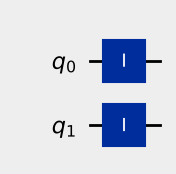

Oráculo de f1


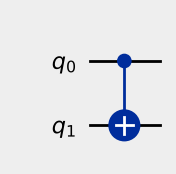

Oráculo de f2


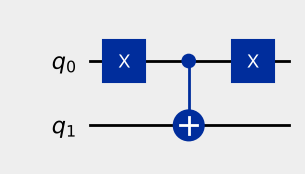

Oráculo de f3


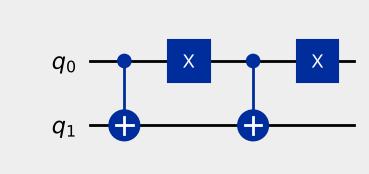

In [ ]:
for caso in range(4):
    print(f"Oráculo de f{caso}")
    display(oraculo_deutsch(caso).draw(output="mpl", style={"backgroundcolor": "#EEEEEE"}))

Em $f_3$ exatamente uma das duas CNOTs dispara para cada $x$, então $q_1$ é invertido sempre. As quatro portas equivalem a $I \otimes X$.

## 3. Conferindo o oráculo com a tabela verdade

A tabela verdade é de $f$, não do circuito. Para ler $f(x)$ no circuito preparamos $q_0 = x$ e $q_1 = 0$. Ao final $q_1$ vale $0 \oplus f(x) = f(x)$.

Se $q_1$ entrasse em 1, sairia com $1 \oplus f(x)$, o complemento de $f(x)$. Por isso a leitura da tabela usa sempre $q_1 = 0$.

In [ ]:
def consulta(caso, x):
    # Prepara |x>|0>, aplica U_f e mede q1, que sai com f(x)
    qc = QuantumCircuit(2, 1)
    if x == 1:
        qc.x(0)
    qc.compose(oraculo_deutsch(caso), inplace=True)
    qc.measure(1, 0)
    contagens = backend.run(transpile(qc, backend), shots=1).result().get_counts()
    return int(list(contagens)[0])

for caso in range(4):
    f0, f1 = consulta(caso, 0), consulta(caso, 1)
    ok = (f0, f1) == (tabela_verdade[caso][0], tabela_verdade[caso][1])
    print(f"f{caso}   f(0) = {f0}   f(1) = {f1}   {'confere' if ok else 'NÃO confere'} com a tabela")

f0   f(0) = 0   f(1) = 0   confere com a tabela
f1   f(0) = 0   f(1) = 1   confere com a tabela
f2   f(0) = 1   f(1) = 0   confere com a tabela
f3   f(0) = 1   f(1) = 1   confere com a tabela


## 4. O circuito de Deutsch

1. Preparar $|0\rangle|1\rangle$
2. Aplicar $H \otimes H$
3. Aplicar $U_f$
4. Aplicar $H \otimes H$
5. Medir $q_0$

$q_1$ entra em $|1\rangle$ e vira $|-\rangle$ depois do Hadamard. Com o auxiliar em $|-\rangle$ o oráculo devolve $f(x)$ como sinal

$$U_f\,|x\rangle|-\rangle = (-1)^{f(x)}\,|x\rangle|-\rangle$$

O Hadamard final em $q_1$ não altera o resultado. Ele aparece porque o circuito do livro e dos slides é simétrico.

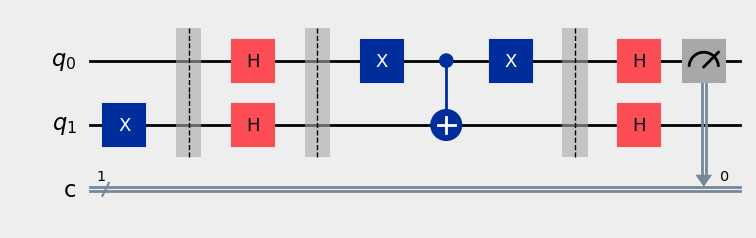

In [ ]:
def circuito_deutsch(oraculo, medir=True):
    qc = QuantumCircuit(2, 1)
    qc.x(1)                          # passo 1, estado |0>|1>
    qc.barrier()
    qc.h([0, 1])                     # passo 2, H ⊗ H
    qc.barrier()
    qc.compose(oraculo, inplace=True)  # passo 3, U_f
    qc.barrier()
    qc.h([0, 1])                     # passo 4, H ⊗ H
    if medir:
        qc.measure(0, 0)             # passo 5, mede o qubit 0
    return qc

display(circuito_deutsch(oraculo_deutsch(2)).draw(output="mpl", style={"backgroundcolor": "#EEEEEE"}))

## 5. Executando o algoritmo

A medida de $q_0$ devolve $f(0) \oplus f(1)$. Resultado 0 indica constante e resultado 1 indica balanceada.

Cada disparo consulta o oráculo uma única vez. Em simulação ideal todos os disparos dão o mesmo bit, porque o algoritmo é determinístico.

In [ ]:
for caso in range(4):
    qc = circuito_deutsch(oraculo_deutsch(caso))
    qc_t = transpile(qc, backend)
    contagens = backend.run(qc_t, shots=1024).result().get_counts()
    tipo = "constante" if contagens.get("0", 0) == 1024 else "balanceada"
    print(f"f{caso} -> {contagens} -> {tipo}  ")

f0 -> {'0': 1024} -> constante  
f1 -> {'1': 1024} -> balanceada  
f2 -> {'1': 1024} -> balanceada  
f3 -> {'0': 1024} -> constante  


## 6. O estado antes da medida

A análise do circuito prevê

$$|\psi_3\rangle = (-1)^{f(0)}\,|f(0) \oplus f(1)\rangle|1\rangle$$

O Qiskit escreve os estados como $q_1 q_0$, então $|10\rangle$ no Qiskit é $|0\rangle|1\rangle$ na notação do livro.

In [ ]:
for caso in range(4):
    psi3 = Statevector(circuito_deutsch(oraculo_deutsch(caso), medir=False))
    for indice, amp in enumerate(psi3.data):
        if abs(amp) > 1e-9:
            print(f"f{caso}  |{indice:02b}>  amplitude {amp.real:+.0f}")

f0  |10>  amplitude +1
f1  |11>  amplitude +1
f2  |11>  amplitude -1
f3  |10>  amplitude -1
